# 07 · Covariance and relationships between variables

Direction and strength of the relationship between pairs of numeric variables, overall and within receptor groups.

**Input:** `analysis_table.csv` (rows with `in_cohort`)  
**Output:** figures `07_*`

Covariance uses divisor *n*. Pearson's *r* is the covariance divided by the product of the two standard deviations; Spearman's *ρ* is the Pearson correlation of the ranks and measures monotonic association.

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def find_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "notebooks").is_dir() and (folder / "data" / "processed" / "analysis_table.csv").is_file():
            return folder.resolve()
    raise FileNotFoundError("Project root not found (needs notebooks/ and data/processed/analysis_table.csv; run notebook 04 first).")

ROOT = find_project_root()
PROC, FIG = ROOT / "data" / "processed", ROOT / "figures" / "phase2"
FIG.mkdir(parents=True, exist_ok=True)

# One colour per meaning in every figure: blue = clinical / positive, orange = molecular / negative, grey = neutral.
POS, NEG, GREY = "#2F6DB5", "#D9822B", "#6B7280"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10,
})

def save_fig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

df = pd.read_csv(PROC / "analysis_table.csv")
co = df[df["in_cohort"]].copy().reset_index(drop=True)
PROLIF = "prolif_score"
print("Analytic cohort:", len(co), "patients")

LAB = {"age": "Age (years)", PROLIF: "Proliferation score", "luminal_score": "Luminal score", "ERBB2": "ERBB2, log2(TPM+1)"}
ER_COLOR = {"Positive": POS, "Negative": NEG}

Analytic cohort: 940 patients


## 1. Pairs

Age is the clinical numeric variable. The scores are the molecular ones. The pairs are age with the proliferation score, age with the luminal score, the luminal score with the proliferation score, and ERBB2 expression with the proliferation score. Points are coloured by ER status.

saved figures\phase2\07_scatter_pairs.png


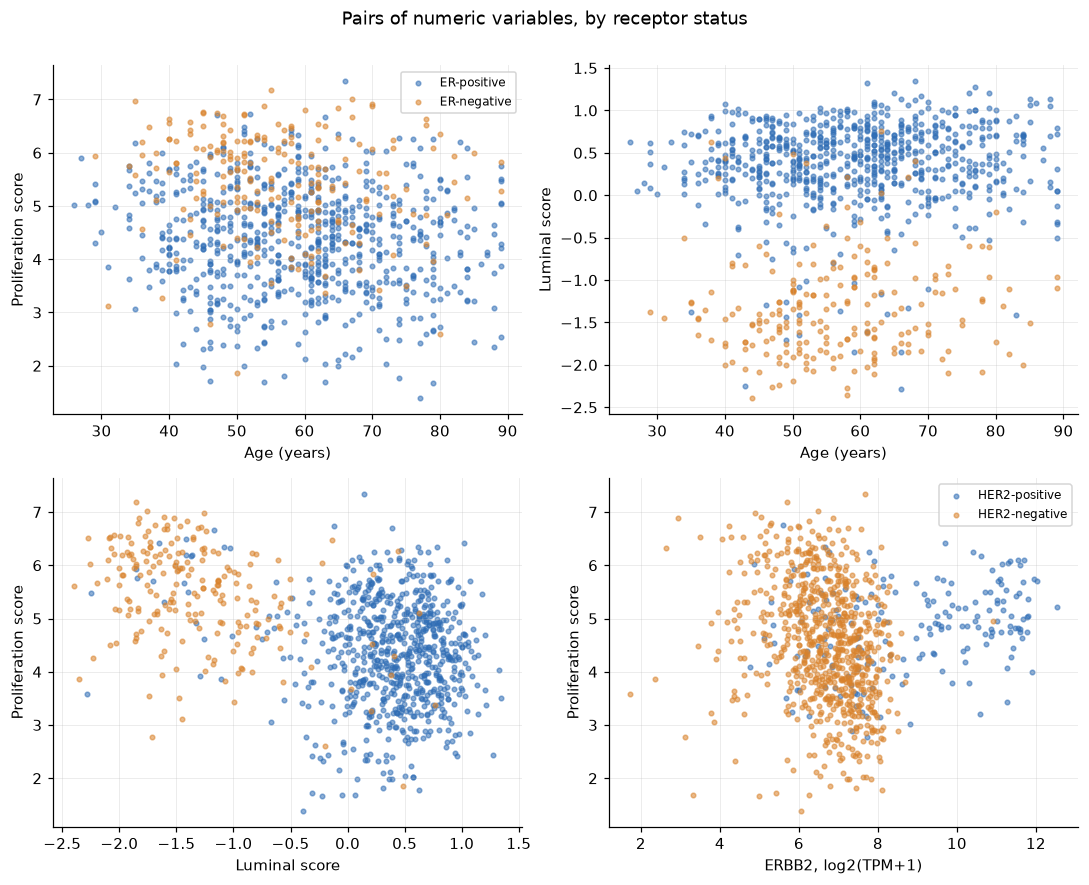

In [15]:
pairs = [("age", PROLIF), ("age", "luminal_score"), ("luminal_score", PROLIF), ("ERBB2", PROLIF)]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (a, b) in zip(axes.ravel(), pairs):
    grouping = "HER2" if (a, b) == ("ERBB2", PROLIF) else "ER"
    for s, c in ER_COLOR.items():
        m = co[grouping] == s
        ax.scatter(co.loc[m, a], co.loc[m, b], s=9, alpha=0.55, color=c, label=f"{grouping}-{s.lower()}")
    ax.set_xlabel(LAB[a]); ax.set_ylabel(LAB[b])
axes[0, 0].legend(fontsize=8)
axes[1, 1].legend(fontsize=8)
fig.suptitle("Pairs of numeric variables, by receptor status", y=1.0)
fig.tight_layout(); save_fig(fig, "07_scatter_pairs"); plt.show()

## 2. Covariance and correlation

*Cov(X, Y) = E[(X − E[X])(Y − E[Y])]*. Its sign gives the direction; its size depends on the units, which Pearson's *r* removes (check: age in months multiplies the covariance by 12 and leaves *r* unchanged).

,x,y,n,covariance,Pearson r,Spearman rho
0,Age (years),Proliferation score,940,-1.917,-0.135,-0.139
1,Age (years),Luminal score,940,1.375,0.119,0.124
2,Luminal score,Proliferation score,940,-0.423,-0.444,-0.375
3,"ERBB2, log2(TPM+1)",Proliferation score,940,-0.055,-0.033,-0.151


age in years:  cov = -1.917, r = -0.135
age in months: cov = -23.001, r = -0.135

Covariance matrix:


,Age (years),Luminal score,"ERBB2, log2(TPM+1)",Proliferation score
Age (years),171.945,1.375,-0.054,-1.917
Luminal score,1.375,0.772,0.307,-0.423
"ERBB2, log2(TPM+1)",-0.054,0.307,2.384,-0.055
Proliferation score,-1.917,-0.423,-0.055,1.174


saved figures\phase2\07_correlation_matrix.png


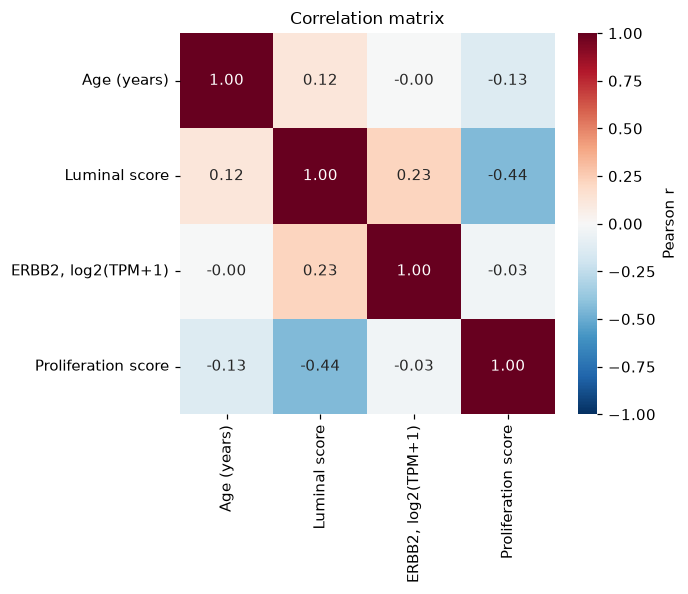

In [16]:
def cov0(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    return np.mean((x - x.mean()) * (y - y.mean()))

rows = []
for a, b in pairs:
    rows.append({"x": LAB[a], "y": LAB[b], "n": len(co), "covariance": cov0(co[a], co[b]),
                 "Pearson r": stats.pearsonr(co[a], co[b])[0], "Spearman rho": stats.spearmanr(co[a], co[b])[0]})
display(pd.DataFrame(rows).round(3))

months = co["age"] * 12
print(f"age in years:  cov = {cov0(co['age'], co[PROLIF]):.3f}, r = {np.corrcoef(co['age'], co[PROLIF])[0, 1]:.3f}")
print(f"age in months: cov = {cov0(months, co[PROLIF]):.3f}, r = {np.corrcoef(months, co[PROLIF])[0, 1]:.3f}")

V = ["age", "luminal_score", "ERBB2", PROLIF]
cm = pd.DataFrame(np.cov(co[V].astype(float).T, ddof=0), index=[LAB[v] for v in V], columns=[LAB[v] for v in V])
cr = co[V].astype(float).corr()
cr.index = cr.columns = [LAB[v] for v in V]
print("\nCovariance matrix:"); display(cm.round(3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix"); ax.grid(False)
save_fig(fig, "07_correlation_matrix"); plt.show()

## 3. Overall and within groups

A group variable can create, hide, or reverse a relationship: if both variables differ between groups, the overall covariance includes a between-group contribution equal to the weighted covariance of the group means around the overall means. The law of total covariance separates the two parts:

*Cov(X, Y) = Σ p_g Cov(X, Y | g) + Σ p_g (E[X | g] − E[X])(E[Y | g] − E[Y])*

The first sum is the weighted average of the within-group covariances, the second the part due to differences between group means. The decomposition is exact for covariance. Correlation is standardised, so the within-group correlations are not weighted averages of the overall *r*.

,x,y,grouping,total cov,within groups,between groups,r overall,n positive,r in positive group,n negative,r in negative group
0,Luminal score,Proliferation score,ER,-0.423,-0.102,-0.321,-0.444,728,-0.138,212,-0.388
1,Age (years),Proliferation score,ER,-1.917,-1.353,-0.564,-0.135,728,-0.096,212,-0.143
2,Age (years),Luminal score,ER,1.375,0.491,0.884,0.119,728,0.075,212,0.067
3,"ERBB2, log2(TPM+1)",Proliferation score,HER2,-0.055,-0.158,0.103,-0.033,182,0.235,758,-0.249


saved figures\phase2\07_relations_within_groups.png


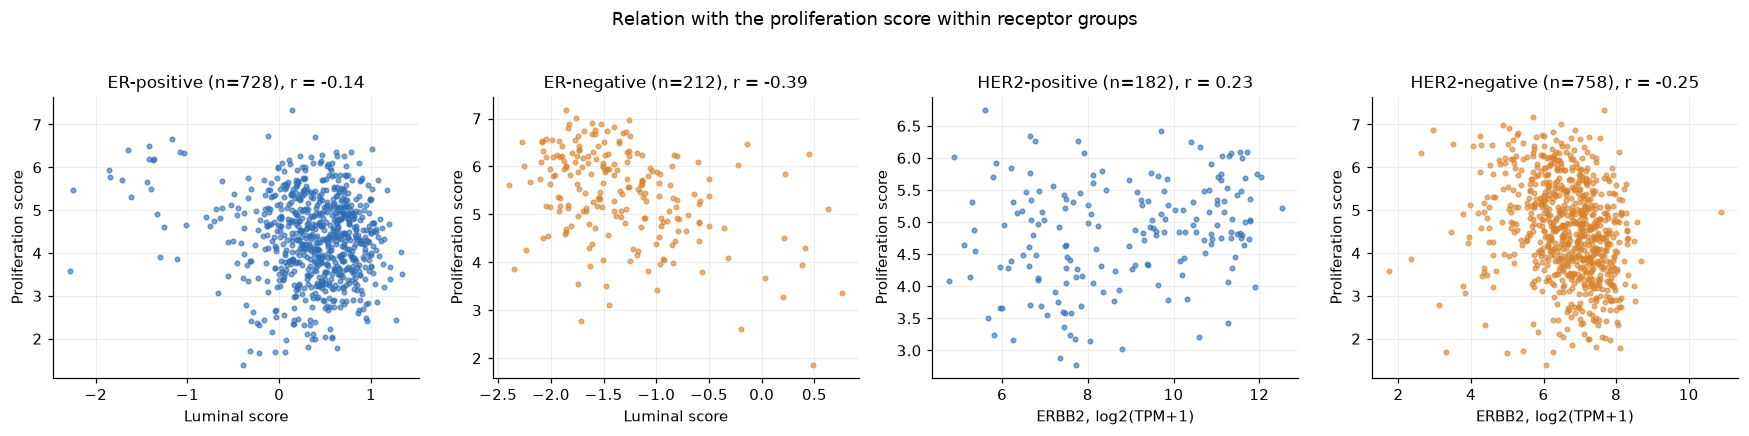

In [17]:
def total_cov(x, y, g):
    d = pd.DataFrame({"x": np.asarray(x, float), "y": np.asarray(y, float), "g": np.asarray(g)})
    p = d.groupby("g").size() / len(d)
    within = sum(p[k] * cov0(s["x"], s["y"]) for k, s in d.groupby("g"))
    mx, my = d.groupby("g")["x"].mean(), d.groupby("g")["y"].mean()
    between = (p * (mx - d["x"].mean()) * (my - d["y"].mean())).sum()
    total = cov0(d["x"], d["y"])
    assert np.isclose(within + between, total)
    return total, within, between

designs = [("luminal_score", PROLIF, "ER"), ("age", PROLIF, "ER"), ("age", "luminal_score", "ER"), ("ERBB2", PROLIF, "HER2")]
rows = []
for a, b, g in designs:
    t, w, bt = total_cov(co[a], co[b], co[g])
    row = {"x": LAB[a], "y": LAB[b], "grouping": g, "total cov": t, "within groups": w, "between groups": bt, "r overall": np.corrcoef(co[a], co[b])[0, 1]}
    for s in ["Positive", "Negative"]:
        m = co[g] == s
        row[f"n {s.lower()}"] = int(m.sum())
        row[f"r in {s.lower()} group"] = np.corrcoef(co.loc[m, a], co.loc[m, b])[0, 1]
    rows.append(row)
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
panels = [("luminal_score", "ER", "Positive"), ("luminal_score", "ER", "Negative"), ("ERBB2", "HER2", "Positive"), ("ERBB2", "HER2", "Negative")]
for ax, (a, g, s) in zip(axes, panels):
    m = co[g] == s
    ax.scatter(co.loc[m, a], co.loc[m, PROLIF], s=9, alpha=0.6, color=POS if s == "Positive" else NEG)
    r = np.corrcoef(co.loc[m, a], co.loc[m, PROLIF])[0, 1]
    ax.set_title(f"{g}-{s.lower()} (n={int(m.sum())}), r = {r:.2f}")
    ax.set_xlabel(LAB[a]); ax.set_ylabel(LAB[PROLIF])
fig.suptitle("Relation with the proliferation score within receptor groups", y=1.03)
fig.tight_layout(); save_fig(fig, "07_relations_within_groups"); plt.show()